In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

# Import data from the database

In [ ]:
conn = sqlite3.connect('customer_churn.db')

sql_query = """
                SELECT name
                FROM sqlite_master
                WHERE type='table'
            """

tables = pd.read_sql(sql_query,conn)

#create dataframe for each table
for table_name in tables['name']:
    df=pd.read_sql(f"SELECT * FROM {table_name}",conn)
    globals()[f"df_{table_name}"]=df
    print(f"Created dataframe: df_{table_name}")

conn.close()

Created dataframe: df_db_customer
Created dataframe: df_db_subscription
Created dataframe: df_db_support


# Data Cleaning

In [ ]:
df_db_customer.head()

,customerid,name,country,state,gender,dob,interests,pincode
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12,travel,NaN
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23,None,NaN
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15,movie,NaN
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30,None,NaN
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05,drama,NaN


In [ ]:
df_db_customer.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   customerid  5000 non-null   object 
 1   name        5000 non-null   object 
 2   country     4997 non-null   object 
 3   state       5000 non-null   object 
 4   gender      5000 non-null   object 
 5   dob         5000 non-null   object 
 6   interests   4983 non-null   object 
 7   pincode     4979 non-null   float64
dtypes: float64(1), object(7)
memory usage: 312.6+ KB


In [ ]:
df_db_customer

,customerid,name,country,state,gender,dob,interests,pincode
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12,travel,NaN
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23,None,NaN
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15,movie,NaN
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30,None,NaN
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05,drama,NaN
...,...,...,...,...,...,...,...,...
4995,4998-RGUXB,chitra,India,Telangana,Female,2004-12-01,job,506001.0
4996,4999-PDPKK,madan,India,Rajasthan,Male,1998-07-20,travel,313001.0
4997,5000-MBDHI,mohan,India,Nagaland,Male,2003-01-20,movie,797103.0
4998,5001-AAIWS,rikim,India,Meghalaya,Female,1995-11-26,drama,793001.0


In [ ]:
# a) Drop columns -> Pincode(whole empty),Interests(Not contributing to churn analysis)
# b) Rename the column name to customer name
# c) Change the datatype of dob column
# d) country column has some missing values so fix that
# e) The gender column is not consistent it has Men,Women listed as gender apart from standard Male,Female

In [ ]:
# a) 
df_db_customer = df_db_customer.drop(columns=['pincode','interests'])

In [ ]:
# b)
df_db_customer=df_db_customer.rename(columns= {'name':'customer_name'})

In [ ]:
# c)
df_db_customer['dob']=pd.to_datetime(df_db_customer['dob'])

In [ ]:
# d)
df_db_customer['gender']=df_db_customer['gender'].replace({'Men':'Male',"Women":'Female'})

In [ ]:
# e) 
df_db_customer[df_db_customer['country'].isna()] # From running this we got to know that the state belongs to country India

# We'll build a map using existing state country combo..
mapping_countries = df_db_customer[['country','state']].dropna(subset=['country']).set_index('state')['country'].to_dict()

df_db_customer['country'] = df_db_customer['country'].fillna(df_db_customer['state'].map(mapping_countries)) 

In [ ]:
# Table 2 -> df_db_subcription

df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,None,None,13.99,627.0,12.0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150.0,91.0
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,None,None,6.99,210.0,34.0
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,None,None,22.99,1725.0,8.0
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195.0,88.0


In [ ]:
# 'None' in the cancellation column represnets that user has not left their subscription is still active.

In [ ]:
df_db_subscription.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customerid               5000 non-null   object 
 1   subscription_start_date  5000 non-null   object 
 2   subscription_type        5000 non-null   object 
 3   renewal_date             5000 non-null   object 
 4   plan_type                5000 non-null   object 
 5   contract_type            5000 non-null   object 
 6   cancellation_date        1432 non-null   object 
 7   cancellation_reason      1432 non-null   object 
 8   monthly_charges          5000 non-null   float64
 9   cltv                     5000 non-null   float64
 10  churn_score              5000 non-null   float64
dtypes: float64(3), object(8)
memory usage: 429.8+ KB


In [ ]:
# Cancellation_date,start_date,renwal_date needs to be changed to datetime
date_cols = ['subscription_start_date','renewal_date','cancellation_date']
df_db_subscription[date_cols]=df_db_subscription[date_cols].apply(pd.to_datetime)

In [ ]:
df_db_subscription.info() # Checking for reflection of the changes done

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customerid               5000 non-null   object        
 1   subscription_start_date  5000 non-null   datetime64[ns]
 2   subscription_type        5000 non-null   object        
 3   renewal_date             5000 non-null   datetime64[ns]
 4   plan_type                5000 non-null   object        
 5   contract_type            5000 non-null   object        
 6   cancellation_date        1432 non-null   datetime64[ns]
 7   cancellation_reason      1432 non-null   object        
 8   monthly_charges          5000 non-null   float64       
 9   cltv                     5000 non-null   float64       
 10  churn_score              5000 non-null   float64       
dtypes: datetime64[ns](3), float64(3), object(5)
memory usage: 429.8+ KB


In [ ]:
# dataframe 3 -> df_db_support
df_db_support.head()

,customerid,complaint_date,escalations,csat_score,col_1,comment
0,0003-MKNFE,2024-08-28,N,60.0,None,service issue
1,0003-MKNFE,2024-08-28,Y,10.0,None,demaned refund
2,0013-EXCHZ,2024-01-20,Y,20.0,None,None
3,0013-MHZWF,2025-03-18,N,90.0,None,guidance to renew
4,0013-SMEOE,2024-11-01,N,30.0,None,None


In [ ]:
df_db_support.tail()

,customerid,complaint_date,escalations,csat_score,col_1,comment
4995,1733-HOBRG,2024-05-31,Y,25.0,None,demaned refund
4996,3687-QVSZH,2025-09-12,N,60.0,None,service issue
4997,4986-VIJEE,2024-01-12,Y,30.0,None,service issue
4998,4685-YCPTU,2025-01-09,N,30.0,None,service issue
4999,0601-UKKTI,2024-01-02,N,90.0,None,received refund


In [ ]:
df_db_support['col_1'].unique()

array([None], dtype=object)

In [ ]:
df_db_support.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   customerid      5000 non-null   object 
 1   complaint_date  5000 non-null   object 
 2   escalations     5000 non-null   object 
 3   csat_score      5000 non-null   float64
 4   col_1           0 non-null      object 
 5   comment         4995 non-null   object 
dtypes: float64(1), object(5)
memory usage: 234.5+ KB


In [ ]:
# Dropping col_1(garbage col) and comment(not worth keeping)
df_db_support=df_db_support.drop(columns=['col_1','comment'])

In [ ]:
# Change the datatype of complaint_date to datetime
df_db_support['complaint_date']=pd.to_datetime(df_db_support['complaint_date'])

In [ ]:
df_db_support.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   customerid      5000 non-null   object        
 1   complaint_date  5000 non-null   datetime64[ns]
 2   escalations     5000 non-null   object        
 3   csat_score      5000 non-null   float64       
dtypes: datetime64[ns](1), float64(1), object(2)
memory usage: 156.4+ KB


# Feature Engineering and Data Analysis

In [ ]:
# Create a new column -> churn flag(Wherever cancellation date exists means flag=1 else 0)
df_db_subscription['churn flag'] = np.where(df_db_subscription['cancellation_date'].notna(),1,0)

In [ ]:
df_db_subscription

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn flag
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,None,13.99,627.0,12.0,0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150.0,91.0,1
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,None,6.99,210.0,34.0,0
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,None,22.99,1725.0,8.0,0
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195.0,88.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...
4995,4998-RGUXB,2022-11-03,Refferal,2024-11-03,Basic,Monthly,2024-11-09,Too expensive,12.99,180.0,76.0,1
4996,4999-PDPKK,2019-02-12,Paid,2025-02-12,Premium,Annual,NaT,None,92.99,1882.0,3.0,0
4997,5000-MBDHI,2020-09-12,Organic,2025-09-12,Standard,Monthly,NaT,None,13.99,709.0,57.0,0
4998,5001-AAIWS,2021-05-12,Paid,2024-05-12,Premium,Annual,2024-06-12,Forgot to cancel trial,12.99,1168.0,87.0,1


In [ ]:
# Merging all of the data into one table

df = df_db_subscription.merge(df_db_customer, on='customerid',how='left').merge(df_db_support,on='customerid',how='left')

In [ ]:
df.shape

(7144, 20)

In [ ]:
# Now in the shape rows seem to have increased so we'll check furthur
df_db_subscription['customerid'].nunique()

5000

In [ ]:
df_db_customer['customerid'].nunique()

5000

In [ ]:
df_db_support['customerid'].nunique()

2856

In [ ]:
# df_db_support seems to have a problem of duplicate customerids mentioned which is normal as some customer could raise a complaint twice
# So we'll keep the latest record from the double entries and make a newq column of complaint raised(Times he/she raised a complaint)

df_db_support['complaint_count']=df_db_support.groupby('customerid')['customerid'].transform('count')

In [ ]:
df_db_support

,customerid,complaint_date,escalations,csat_score,complaint_count
0,0003-MKNFE,2024-08-28,N,60.0,6
1,0003-MKNFE,2024-08-28,Y,10.0,6
2,0013-EXCHZ,2024-01-20,Y,20.0,2
3,0013-MHZWF,2025-03-18,N,90.0,1
4,0013-SMEOE,2024-11-01,N,30.0,5
...,...,...,...,...,...
4995,1733-HOBRG,2024-05-31,Y,25.0,1
4996,3687-QVSZH,2025-09-12,N,60.0,3
4997,4986-VIJEE,2024-01-12,Y,30.0,1
4998,4685-YCPTU,2025-01-09,N,30.0,3


In [ ]:
df_db_support=df_db_support.sort_values('complaint_date').drop_duplicates('customerid',keep='last')

In [ ]:
df_db_support['customerid'].nunique()

2856

In [ ]:
# Now we can merge
df = df_db_subscription.merge(df_db_customer, on='customerid',how='left').merge(df_db_support,on='customerid',how='left')

In [ ]:
df.shape

(5000, 21)

In [ ]:
df.to_csv('churn_5000.csv')

# Data Analysis

In [ ]:
# 1. Churn rate
churn_rate = df['churn flag'].mean()* 100
print("Churn Rate: ",round(churn_rate,2),"%")

Churn Rate:  28.64 %


In [ ]:
# Retention rate
retention_rate = 100-churn_rate
print("Retention Rate: ",round(retention_rate,2),"%")

Retention Rate:  71.36 %


In [ ]:
# Plan Type wise churn rate
df.groupby('plan_type')['churn flag'].mean()*100

plan_type
Basic       60.640138
Premium     14.578454
Standard    22.565543
Name: churn flag, dtype: float64

In [ ]:
# Churn by state + revenue loss + count of users lost
df.groupby('state').agg({'churn flag':'mean','monthly_charges':'sum','customerid':'count'}).rename(columns={'churn flag':'churn_rate','monthly_charges':'revenue_lost','customerid':'count'})

,churn_rate,revenue_lost,count
state,,,
Delhi,0.297669,17912.56,944
Karnataka,0.272541,8896.12,488
Kathmandu,0.284444,8885.50,450
Maharashtra,0.293388,13509.74,726
Meghalaya,0.282123,13040.84,716
Nagaland,0.257261,4835.59,241
Rajasthan,0.329218,9388.14,486
Telangana,0.253086,9127.14,486
Uttar Pradesh,0.280778,8558.37,463


In [ ]:
# Churn by subscription_type + revenue loss + count of users lost
df.groupby('subscription_type').agg({'churn flag':'mean','monthly_charges':'sum','customerid':'count'}).rename(columns={'churn flag':'churn_rate','monthly_charges':'revenue_lost','customerid':'count'})

,churn_rate,revenue_lost,count
subscription_type,,,
Organic,0.000000,35262.50,2150
Paid,0.171843,41368.51,1449
Refferal,0.844397,17522.99,1401


In [ ]:
# ARPU - Average revenue per user
arpu = df['monthly_charges'].mean().round(2)
print('Average Revenue Per User = ',arpu)

Average Revenue Per User =  18.83


In [ ]:
# Average Customer Tenure -> subcription_start_date - cancellation_date (If NaT then consider todays date)
today = pd.to_datetime('today')
df['tenure_days'] = np.where(df['cancellation_date'].notna(),
                            (df['cancellation_date'] - df['subscription_start_date']).dt.days,
                            (today - df['subscription_start_date']).dt.days)

avg_tenure = df['tenure_days'].mean().round()
print("Average tenure of user: ",int(avg_tenure),"days")

Average tenure of user:  1715 days


In [ ]:
# Calculate customer age

df['customer_age'] = ((today - df['dob']).dt.days/365).round()
df

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,...,country,state,gender,dob,complaint_date,escalations,csat_score,complaint_count,tenure_days,customer_age
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,None,13.99,627.0,...,India,Maharashtra,Male,1982-04-12,NaT,NaN,NaN,NaN,2061.0,45.0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150.0,...,India,Karnataka,Male,1995-11-23,2024-09-22,Y,25.0,6.0,1501.0,31.0
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,None,6.99,210.0,...,India,Delhi,Female,1978-02-15,NaT,NaN,NaN,NaN,1446.0,49.0
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,None,22.99,1725.0,...,India,Nagaland,Male,2001-08-30,NaT,NaN,NaN,NaN,2736.0,25.0
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195.0,...,India,Delhi,Female,1990-05-05,2024-01-20,Y,20.0,2.0,419.0,37.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,4998-RGUXB,2022-11-03,Refferal,2024-11-03,Basic,Monthly,2024-11-09,Too expensive,12.99,180.0,...,India,Telangana,Female,2004-12-01,2024-12-04,Y,25.0,1.0,737.0,22.0
4996,4999-PDPKK,2019-02-12,Paid,2025-02-12,Premium,Annual,NaT,None,92.99,1882.0,...,India,Rajasthan,Male,1998-07-20,NaT,NaN,NaN,NaN,2823.0,28.0
4997,5000-MBDHI,2020-09-12,Organic,2025-09-12,Standard,Monthly,NaT,None,13.99,709.0,...,India,Nagaland,Male,2003-01-20,2024-11-21,Y,25.0,1.0,2245.0,24.0
4998,5001-AAIWS,2021-05-12,Paid,2024-05-12,Premium,Annual,2024-06-12,Forgot to cancel trial,12.99,1168.0,...,India,Meghalaya,Female,1995-11-26,2024-05-08,Y,30.0,1.0,1127.0,31.0


In [ ]:
# Revenue at risk - revenue lost from churned users
revenue_lost = df[df['churn flag'] == 1]['monthly_charges'].sum()
print('Revenue lost: ',revenue_lost)

Revenue lost:  17707.68


In [ ]:
# Escalation Rate
escalation_rate = ((df['escalations'] == 'Y').mean()*100).round(2)
print('Escalation_rate : ',escalation_rate)

Escalation_rate :  25.26


In [ ]:
# Average Complaint Per user
avg_complaint = df['complaint_count'].sum()/df['customerid'].count()
print("Average Complaint per User : ",avg_complaint)

Average Complaint per User :  1.0


In [ ]:
# Correlation Escalation vs Churn

# First of all put 1 for Y and 0 for N
df['escalations'] = np.where(df['escalations'] == 'Y',1,0)

In [ ]:
corr_df = df[['escalations','churn flag']].dropna()
correlation = corr_df['escalations'].corr(df['churn flag'])
print("Correlation between esclation vs churn is = ", round(correlation, 2))

Correlation between esclation vs churn is =  0.42


In [ ]:

# 11. ghurn risk - create a column using existing col
conditions = [
(df['churn_score'] < 50),
(df['churn_score'] >= 50) & (df['churn_score'] < 70),
(df['churn_score'] >= 70)]

choices = ['low', 'med', 'high']

df['churn_risk'] = np.select(conditions, choices, default='unkown')

In [ ]:
df[['churn_score','churn_risk']].head()

,churn_score,churn_risk
0,12.0,low
1,91.0,high
2,34.0,low
3,8.0,low
4,88.0,high


In [ ]:
# Making a copy of df for visualization
df_visual = df.copy()

# Visualization using Matplotlib

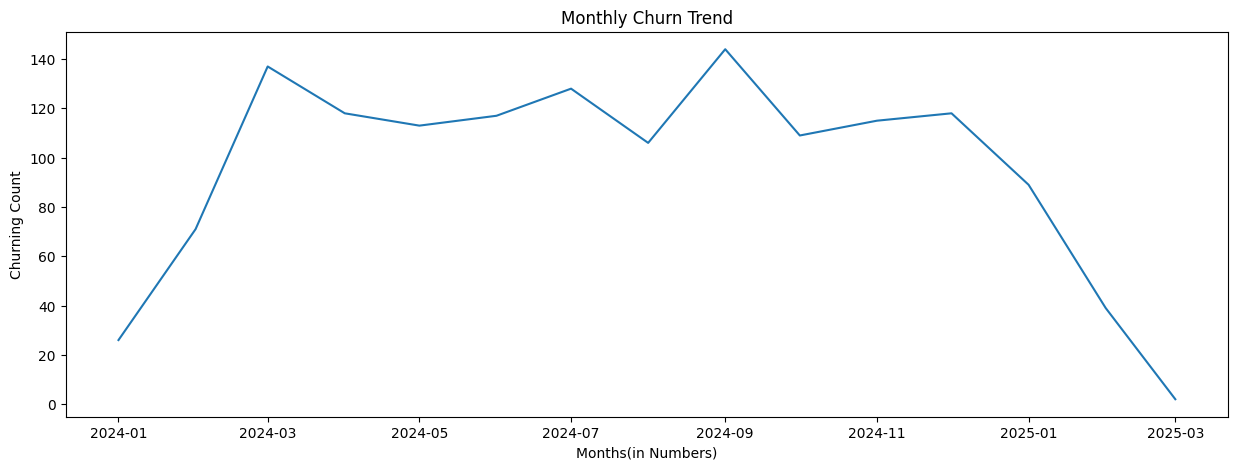

In [ ]:
# Monthly Churn Trend
# df_visual['cancellation_date'] = df_visual['cancellation_date'].dt.month

churn_trend = (
    df_visual[df_visual['churn flag'] == 1]
    .groupby(pd.Grouper(key='cancellation_date', freq='MS'))
    ['customerid']
    .nunique()
)

# Plotting a line chart for the same
plt.figure(figsize=(15,5))
plt.plot(churn_trend.index,churn_trend.values)
plt.title('Monthly Churn Trend')
plt.xlabel('Months(in Numbers)')
plt.ylabel('Churning Count')
plt.show()

<BarContainer object of 3 artists>

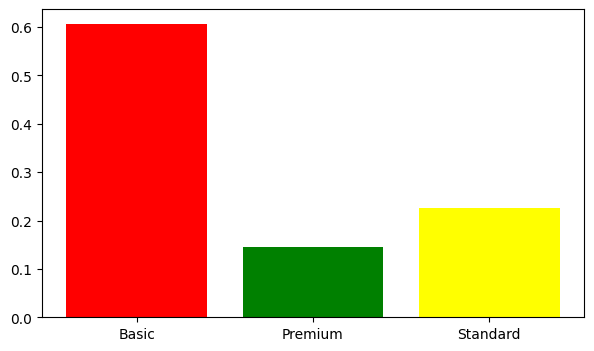

In [ ]:
# Churn By Plan type
churn_trend_planwise = df_visual.groupby('plan_type')['churn flag'].mean()

color = ['red','green','yellow']

plt.figure(figsize=(7,4))
plt.bar(churn_trend_planwise.index,churn_trend_planwise.values,color=color)


<BarContainer object of 9 artists>

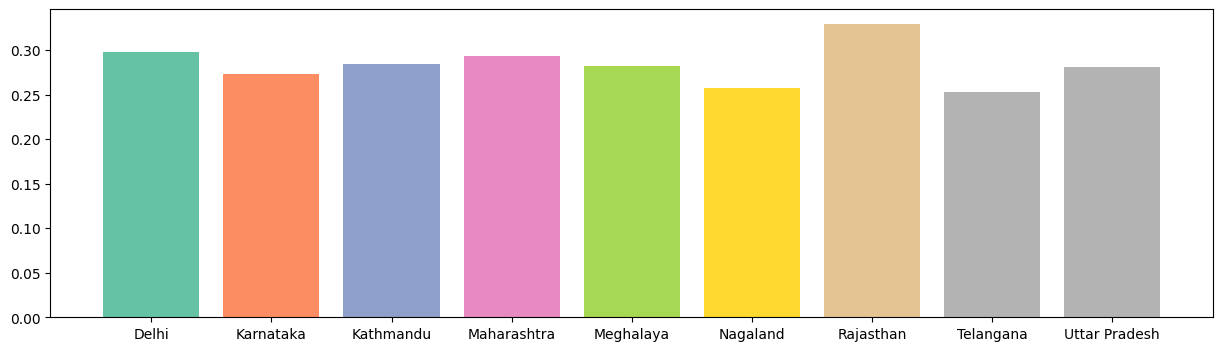

In [ ]:
# churn by states
churn_trend_statewise = df_visual.groupby('state')['churn flag'].mean()

color = plt.cm.Set2(np.linspace(0,1,len(churn_trend_statewise)))

plt.figure(figsize=(15,4))
plt.bar(churn_trend_statewise.index,churn_trend_statewise.values,color=color)

# Visualization using Seaborn in order to create a heatmap

In [ ]:
# As we know heatmap is created using numerical columns only so in order to create a heatmap between categorical columns 
# we have to give them numbering but numbering has to be given in an order so we did order mapping based on their categorical priority.

In [ ]:
df_encoded = df_visual[['plan_type','contract_type','churn_score','churn flag','churn_risk','escalations']]

order_mappings = {
    'plan_type' : ['Basic','Standard','Premium'],
    'contract_type' : ['Monthly','Annual'],
    'churn_risk' : ['low','med','high']
}

for col, order in order_mappings.items():
    df_encoded[col] = pd.Categorical(df_encoded[col].astype('category'), categories=order, ordered=True).codes

C:\Users\DELL\AppData\Local\Temp\ipykernel_27428\2469401388.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_encoded[col] = pd.Categorical(df_encoded[col].astype('category'), categories=order, ordered=True).codes
C:\Users\DELL\AppData\Local\Temp\ipykernel_27428\2469401388.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_encoded[col] = pd.Categorical(df_encoded[col].astype('category'), categories=order, ordered=True).codes
C:\Users\DELL\AppData\Local\Temp\ipykernel_27428\2469401388.py:10: Setti

In [ ]:
df_encoded.head()

,plan_type,contract_type,churn_score,churn flag,churn_risk,escalations
0,1,1,12.0,0,0,0
1,2,1,91.0,1,2,1
2,0,0,34.0,0,0,0
3,2,1,8.0,0,0,0
4,1,0,88.0,1,2,1


<Axes: >

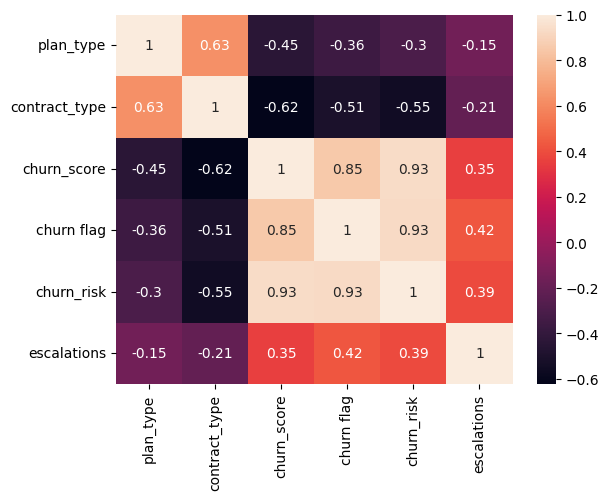

In [ ]:
# Creating the Heatmap -> Also used to find patterns within the dataset

sns.heatmap(df_encoded.corr(), annot=True)

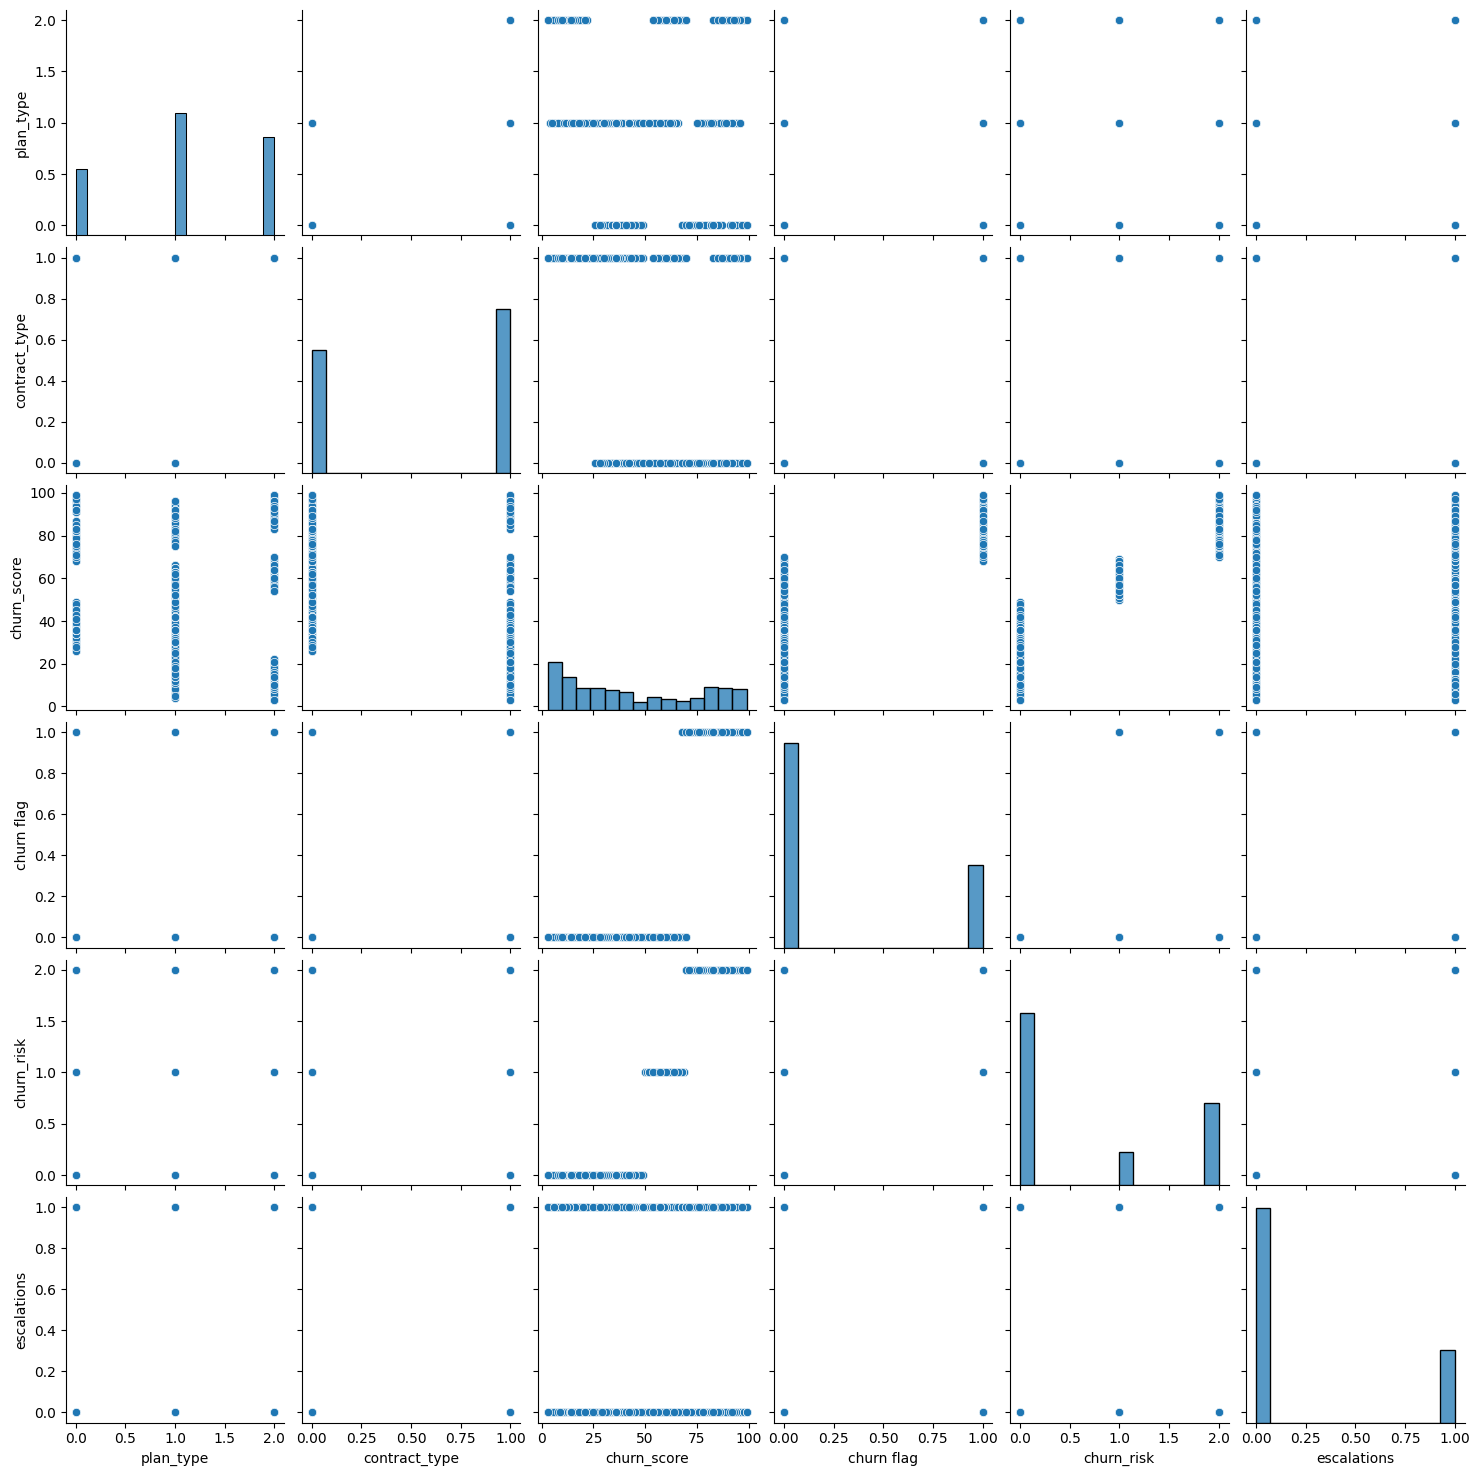

In [ ]:
# pairplot -> Used to find patterns within the dataset
sns.pairplot(df_encoded)

In [ ]:
# Thing to note that for using matplotlib if your data is not much aggregated and sorted then its fine
# But in seaborn your data should be aggregated and sorted and in proper manner.

# Also in matplotlib creating a heatmap is a headache so we use seaborn

In [ ]:
df_visual['escalations']

0       0
1       1
2       0
3       0
4       1
       ..
4995    1
4996    0
4997    1
4998    1
4999    0
Name: escalations, Length: 5000, dtype: int64